# LightGBM: Histogram, GOSS, and Feature Bundling

Compare three LightGBM training configurations on the heart-disease dataset: the standard histogram-based GBDT baseline, Gradient-based One-Side Sampling (GOSS), and Exclusive Feature Bundling (EFB). This is an educational example only, not for medical diagnosis.

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from sklearn.base import clone

RANDOM_STATE = 42
print(f"LightGBM version: {lgb.__version__}")

LightGBM version: 4.7.0


In [2]:
!pip install lightgbm


  Using cached lightgbm-4.7.0-py3-none-win_amd64.whl.metadata (18 kB)
Using cached lightgbm-4.7.0-py3-none-win_amd64.whl (1.4 MB)


## 1. Load and prepare the data

The source target `num` ranges from 0 to 4. We treat 0 as no disease and any value above 0 as disease. Identifier and source columns are excluded from model features.

In [4]:
data_path_candidates = [
    Path("classification") / "heart_disease_uci.csv",
    Path("..") / "classification" / "heart_disease_uci.csv",
]
data_path = next((path for path in data_path_candidates if path.exists()), None)
if data_path is None:
    raise FileNotFoundError(
        "Could not find classification/heart_disease_uci.csv. "
        "Run this notebook from the repository root or the 'xg boost' folder."
    )

data = pd.read_csv(data_path)
if "num" not in data.columns:
    raise ValueError("Expected the target column 'num' in the heart-disease dataset.")

data = data.dropna(subset=["num"]).copy()
data["target"] = (data["num"] > 0).astype(int)
excluded_columns = {"id", "dataset", "num", "target"}
feature_columns = [column for column in data.columns if column not in excluded_columns]
if not feature_columns:
    raise ValueError("No usable feature columns were found.")

X = data[feature_columns]
y = data["target"]
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

print(f"Loaded {len(data)} rows from {data_path}")
print(f"Features: {len(feature_columns)}")
display(y.value_counts().sort_index().rename(index={0: "No disease", 1: "Disease"}).to_frame("count"))

data.head()

Loaded 920 rows from ..\classification\heart_disease_uci.csv
Features: 13


,count
target,
No disease,411
Disease,509


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num,target
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2,1
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0,0


In [5]:
numeric_features

['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']

In [6]:
categorical_features

['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']

In [7]:
data.shape

(920, 17)

## 2. Split the data

A stratified split keeps the class proportions similar in training and testing sets. Preprocessing is fitted only on training data.

In [8]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)
print(f"Training rows: {len(X_train)}")
print(f"Test rows: {len(X_test)}")

Training rows: 736
Test rows: 184


In [9]:
X_train

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal
640,53,Male,non-anginal,160.0,0.0,NaN,lv hypertrophy,122.0,True,0.0,NaN,NaN,reversable defect
743,74,Male,non-anginal,NaN,0.0,False,normal,NaN,NaN,NaN,NaN,NaN,NaN
890,53,Male,asymptomatic,124.0,243.0,False,normal,122.0,True,2.0,flat,NaN,reversable defect
270,61,Male,asymptomatic,140.0,207.0,False,lv hypertrophy,138.0,True,1.9,upsloping,1.0,reversable defect
654,56,Male,non-anginal,155.0,0.0,False,st-t abnormality,99.0,False,0.0,flat,NaN,normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...
833,72,Male,asymptomatic,NaN,211.0,False,normal,NaN,NaN,NaN,NaN,NaN,NaN
242,49,Female,asymptomatic,130.0,269.0,False,normal,163.0,False,0.0,upsloping,0.0,normal
709,66,Male,asymptomatic,150.0,0.0,False,normal,108.0,True,2.0,flat,NaN,reversable defect
21,58,Female,typical angina,150.0,283.0,True,lv hypertrophy,162.0,False,1.0,upsloping,0.0,normal


## 3. Preprocess and train three LightGBM configurations

Missing numeric values are filled with the training median, and missing categories with the most frequent value. Categories are one-hot encoded and the transformed matrix is kept sparse so EFB can bundle mutually exclusive one-hot features. LightGBM uses histogram-based split finding for all three models. The configurations below are: **1) histogram-based GBDT**, **2) GOSS** (`data_sample_strategy="goss"`), and **3) EFB feature bundling** (`enable_bundle=True`). EFB is disabled in the first two models and enabled in the third to make its effect explicit.

In [10]:
numeric_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
])
categorical_preprocessing = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessing, numeric_features),
        ("categorical", categorical_preprocessing, categorical_features),
    ],
    sparse_threshold=1.0,
)

common_model_params = {
    "objective": "binary",
    "n_estimators": 100,
    "learning_rate": 0.05,
    "num_leaves": 15,
    "max_depth": 4,
    "max_bin": 63,
    "n_jobs": -1,
    "random_state": RANDOM_STATE,
    "verbosity": -1,
}

model_configs = {
    "Histogram-based GBDT": lgb.LGBMClassifier(
        **common_model_params,
        enable_bundle=False,
    ),
    "GOSS": lgb.LGBMClassifier(
        **common_model_params,
        data_sample_strategy="goss",
        top_rate=0.2,
        other_rate=0.1,
        enable_bundle=False,
    ),
    "Feature bundling (EFB)": lgb.LGBMClassifier(
        **common_model_params,
        enable_bundle=True,
    ),
}

classifiers = {}
for model_name, model in model_configs.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", model),
    ])
    pipeline.fit(X_train, y_train)
    classifiers[model_name] = pipeline
    print(f"Trained {model_name}")

# Keep a consistent reference model for the later single-model plots and example predictions.
classifier = classifiers["Histogram-based GBDT"]

Trained Histogram-based GBDT
Trained GOSS
Trained Feature bundling (EFB)


In [11]:
fitted_preprocessor = classifier.named_steps["preprocessor"]
matrix = fitted_preprocessor.transform(X_train)

# Convert sparse output to a regular array for display
if hasattr(matrix, "toarray"):
    matrix = matrix.toarray()

feature_matrix = pd.DataFrame(
    matrix,
    columns=fitted_preprocessor.get_feature_names_out(),
    index=X_train.index,
)

print("Matrix shape:", feature_matrix.shape)
display(feature_matrix.head())

Matrix shape: (736, 25)


,numeric__age,numeric__trestbps,numeric__chol,numeric__thalch,numeric__oldpeak,numeric__ca,categorical__sex_Female,categorical__sex_Male,categorical__cp_asymptomatic,categorical__cp_atypical angina,...,categorical__restecg_normal,categorical__restecg_st-t abnormality,categorical__exang_False,categorical__exang_True,categorical__slope_downsloping,categorical__slope_flat,categorical__slope_upsloping,categorical__thal_fixed defect,categorical__thal_normal,categorical__thal_reversable defect
640,53.0,160.0,0.0,122.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
743,74.0,130.0,0.0,140.0,0.5,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
890,53.0,124.0,243.0,122.0,2.0,0.0,0.0,1.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
270,61.0,140.0,207.0,138.0,1.9,1.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
654,56.0,155.0,0.0,99.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [12]:
categorical_preprocessing

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('imputer', ...), ('one_hot', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation

In [13]:
classifier.named_steps["preprocessor"].feature_names_in_

array(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch',
       'exang', 'oldpeak', 'slope', 'ca', 'thal'], dtype=object)

## 4. Evaluate on the held-out test set

Compare the three configurations using the same held-out test split. Review several metrics rather than accuracy alone; precision and recall describe different types of classification errors. The histogram-based GBDT is used for the example plots below so model selection does not use test-set results.

,Accuracy,Precision,Recall,F1 score,ROC-AUC
Histogram-based GBDT,0.842,0.835,0.892,0.863,0.924
GOSS,0.859,0.852,0.902,0.876,0.919
Feature bundling (EFB),0.842,0.835,0.892,0.863,0.924


              precision    recall  f1-score   support

  No disease       0.85      0.78      0.82        82
     Disease       0.83      0.89      0.86       102

    accuracy                           0.84       184
   macro avg       0.84      0.84      0.84       184
weighted avg       0.84      0.84      0.84       184



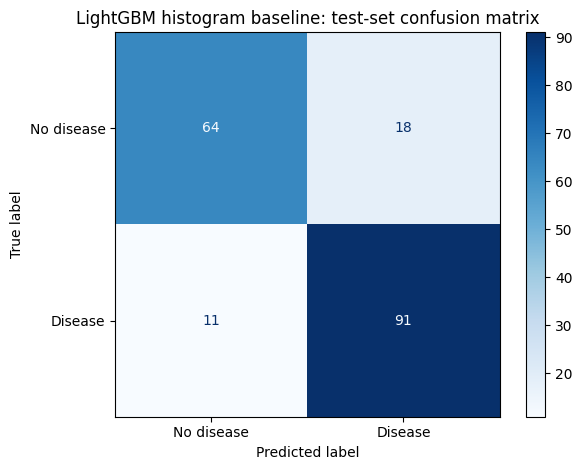

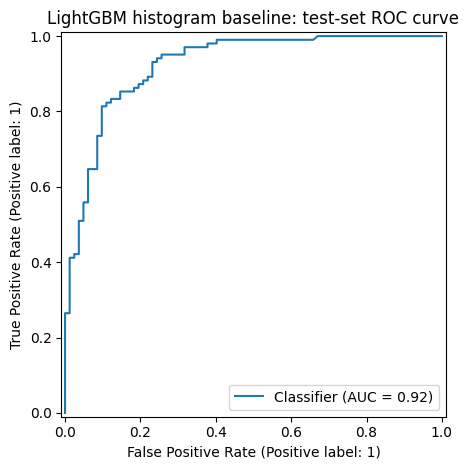

In [14]:
evaluation_rows = {}
test_predictions = {}
test_probabilities = {}
for model_name, pipeline in classifiers.items():
    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    test_predictions[model_name] = predictions
    test_probabilities[model_name] = probabilities
    evaluation_rows[model_name] = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
    }

comparison = pd.DataFrame.from_dict(evaluation_rows, orient="index")
display(comparison.round(3))

baseline_name = "Histogram-based GBDT"
y_pred = test_predictions[baseline_name]
y_probability = test_probabilities[baseline_name]

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["No disease", "Disease"],
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["No disease", "Disease"], cmap="Blues"
)
plt.title("LightGBM histogram baseline: test-set confusion matrix")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, y_probability)
plt.title("LightGBM histogram baseline: test-set ROC curve")
plt.tight_layout()
plt.show()

## 5. Inspect feature importance and predict a sample

Feature importance shows how the fitted trees used features; it does not show cause and effect. The sample prediction below is taken from the test set.

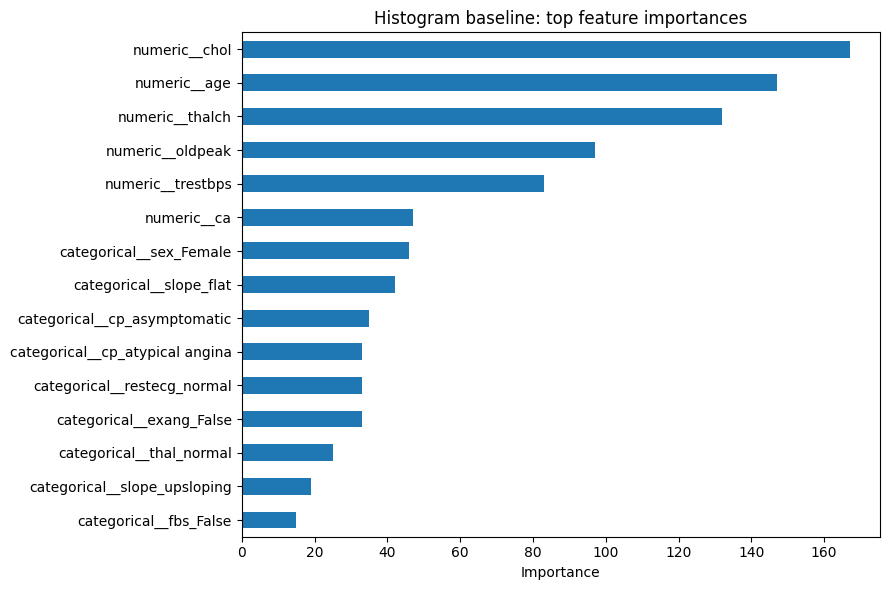

Predicted class: 0 (0 = no disease, 1 = disease)
Estimated disease probability: 29.0%
Actual class: 1


In [15]:
preprocessor_fitted = classifier.named_steps["preprocessor"]
model_fitted = classifier.named_steps["model"]
feature_names = preprocessor_fitted.get_feature_names_out()
feature_importance = (
    pd.Series(model_fitted.feature_importances_, index=feature_names)
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)
feature_importance.plot(kind="barh", figsize=(9, 6), title="Histogram baseline: top feature importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

sample_patient = X_test.iloc[[0]]
predicted_class = int(classifier.predict(sample_patient)[0])
disease_probability = float(classifier.predict_proba(sample_patient)[0, 1])
print(f"Predicted class: {predicted_class} (0 = no disease, 1 = disease)")
print(f"Estimated disease probability: {disease_probability:.1%}")
print(f"Actual class: {int(y_test.iloc[0])}")

## Recap

This notebook loads the repository's heart-disease data, splits it without leaking test data into preprocessing, and compares LightGBM's histogram-based GBDT, GOSS sampling, and EFB feature bundling. This example is for education only and must not be used to diagnose or make health decisions.

## Manual input prediction

Enter values for a new patient below. Press Enter at any prompt to use a suggested default from the training data. This example is for learning only, not medical diagnosis.

In [16]:
print("Enter patient feature values. Press Enter to use the suggested default.\n")
manual_patient = {}

for column in feature_columns:
    values = X_train[column].dropna()
    if column in numeric_features:
        default_value = values.median()
        raw_value = input(f"{column} (number, default {default_value:g}): ").strip()
        manual_patient[column] = float(raw_value) if raw_value else float(default_value)
    else:
        default_value = values.mode().iloc[0]
        categories = values.astype(str).unique().tolist()
        print(f"  Options: {', '.join(categories[:10])}")
        raw_value = input(f"{column} (default {default_value}): ").strip()
        manual_patient[column] = raw_value if raw_value else default_value

manual_input = pd.DataFrame([manual_patient], columns=feature_columns)
manual_prediction = int(classifier.predict(manual_input)[0])
manual_probability = float(classifier.predict_proba(manual_input)[0, 1])

print("\nManual input prediction:")
print("Result: Disease detected" if manual_prediction == 1 else "Result: No disease detected")
print(f"Predicted class: {manual_prediction} (0 = no disease, 1 = disease)")
print(f"Estimated probability of disease: {manual_probability:.1%}")

Enter patient feature values. Press Enter to use the suggested default.

  Options: Male, Female
  Options: non-anginal, asymptomatic, atypical angina, typical angina
  Options: False, True
  Options: lv hypertrophy, normal, st-t abnormality
  Options: True, False
  Options: flat, upsloping, downsloping
  Options: reversable defect, normal, fixed defect

Manual input prediction:
Result: Disease detected
Predicted class: 1 (0 = no disease, 1 = disease)
Estimated probability of disease: 58.9%
